# NNGLS Analysis of BCEF Forest Data

Spatial regression of percent tree cover (PTC) on forest canopy height (FCH) for the
Bonanza Creek Experimental Forest (BCEF) dataset, comparing three approaches:

- **NN + kriging**: a plain neural network mean function with kriging on the residuals
- **NNGLS**: neural network generalized least squares (`geospaNN`), which jointly accounts for spatial correlation during training
- **Linear kriging (BRISC)**: a linear mean with spatial kriging as a baseline

The test set is held out as a spatial block (a corner region) so that prediction is
genuinely extrapolative in space.

## Imports and setup

`matplotlib` uses the `TkAgg` backend in the original script for interactive windows.
Inside a notebook you will usually want the inline backend instead, so the `%matplotlib inline`
magic is included. Swap it back to `matplotlib.use('TkAgg')` if you want pop-out figures.

In [1]:
import copy
import time

import torch
import geospaNN
import numpy as np
import pandas as pd

import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt

# In a notebook, prefer inline figures. Uncomment the TkAgg line for pop-out windows.
%matplotlib inline
# matplotlib.use('TkAgg')

R callback write-console: Loading required package: BRISC
  
R callback write-console: Loading required package: RANN
  
R callback write-console: Loading required package: parallel
  
R callback write-console: Loading required package: rdist
  
R callback write-console: Loading required package: matrixStats
  
R callback write-console: Loading required package: pbapply
  
R callback write-console: The ordering of inputs x (covariates) and y (response) in BRISC_estimation has been changed BRISC 1.0.0 onwards.
  Please check the new documentation with ?BRISC_estimation.
  


R package: BRISC installed


/opt/anaconda3/envs/geomed2026/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the data

Read the raw BCEF CSV and build a `GeoDataFrame`. The coordinates are stored in an
Albers Equal Area projection (units in km); reproject to WGS84 (EPSG:4326) for
lon/lat plotting.

In [3]:
combined_data = pd.read_csv('RealData_BCEF.csv')

# Build a GeoDataFrame and reproject from the BCEF Albers projection to lon/lat.
gdf = gpd.GeoDataFrame(
    combined_data,
    geometry=gpd.points_from_xy(combined_data.x, combined_data.y)
)
gdf = gdf.set_crs(
    "+proj=aea +lat_1=55 +lat_2=65 +lat_0=50 +lon_0=-154 "
    "+x_0=0 +y_0=0 +ellps=GRS80 +towgs84=0,0,0,0,0,0,0 +units=km +no_defs"
)
gdf = gdf.to_crs("EPSG:4326")

combined_data.head()

,Unnamed: 0,x,y,FCH,PTC,holdout
0,1,259.164423,1649.552153,21.990000,86.457535,1
1,2,259.165806,1649.539216,21.730000,86.457535,1
2,3,259.167189,1649.526279,22.440001,85.202626,1
3,4,259.177347,1649.553536,22.990000,86.457535,1
4,5,259.178730,1649.540598,22.959999,86.457535,1


## Spatial distribution of the full dataset

Maps of FCH and PTC over the full BCEF extent.

<Figure size 640x480 with 0 Axes>

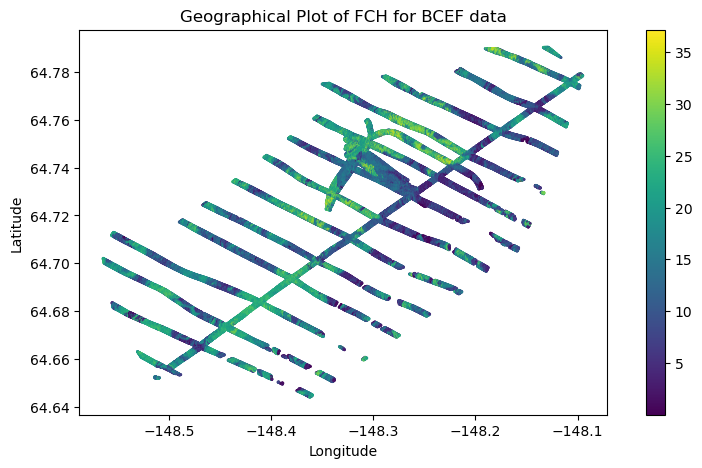

<Figure size 640x480 with 0 Axes>

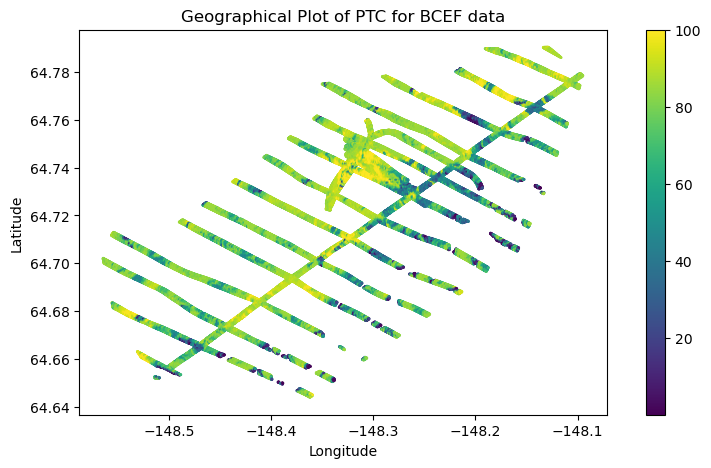

In [5]:
for variable in ['FCH', 'PTC']:
    plt.clf()
    gdf.plot(column=variable, cmap='viridis', legend=True, figsize=(10, 5), markersize=1)
    plt.title('Geographical Plot of ' + variable + ' for BCEF data')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.show()

## PTC vs FCH scatter (full data)

<Figure size 640x480 with 0 Axes>

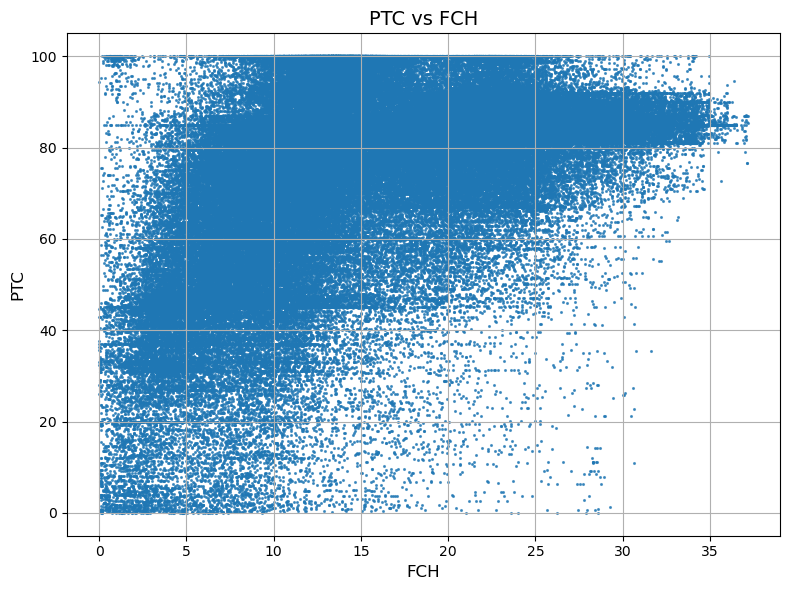

In [6]:
plt.clf()
plt.figure(figsize=(8, 6))
plt.scatter(np.array(combined_data['FCH']), np.array(combined_data['PTC']),
            s=1.5, alpha=0.7)
plt.title('PTC vs FCH', fontsize=14)
plt.xlabel('FCH', fontsize=12)
plt.ylabel('PTC', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

## Subsample, clean, and build model tensors

Draw 80,000 points, drop missing values, and trim the top 5% of PTC to remove the
heavy upper tail. The predictor `X` is FCH, the response `Y` is PTC, and `coord`
holds the lon/lat coordinates rescaled to the unit square (so the spatial range
parameter is on a comparable scale across dimensions).

In [7]:
combined_data_subsample = gdf.sample(n=80000, random_state=42)
combined_data_subsample = combined_data_subsample.dropna()
combined_data_subsample = combined_data_subsample[
    combined_data_subsample['PTC'] < np.quantile(combined_data_subsample['PTC'], 0.95)
]
combined_data_subsample["latitude"] = combined_data_subsample.geometry.y
combined_data_subsample["longitude"] = combined_data_subsample.geometry.x

X = torch.from_numpy(combined_data_subsample[['FCH']].to_numpy()).float()
Y = torch.from_numpy(combined_data_subsample[['PTC']].to_numpy()).float().reshape(-1)
coord = torch.from_numpy(combined_data_subsample[["longitude", "latitude"]].to_numpy()).float()

# Rescale coordinates to the unit square.
coord[:, 0] = (coord[:, 0] - min(coord[:, 0])) / (max(coord[:, 0]) - min(coord[:, 0]))
coord[:, 1] = (coord[:, 1] - min(coord[:, 1])) / (max(coord[:, 1]) - min(coord[:, 1]))

## PTC vs FCH scatter (subsampled data)

<Figure size 640x480 with 0 Axes>

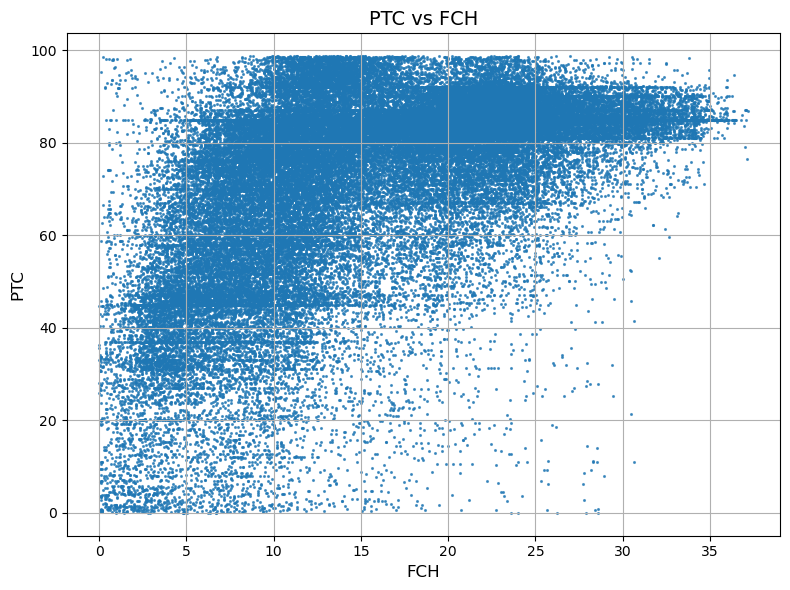

In [8]:
plt.clf()
plt.figure(figsize=(8, 6))
plt.scatter(np.array(combined_data_subsample['FCH']), np.array(combined_data_subsample['PTC']),
            s=1.5, alpha=0.7)
plt.title('PTC vs FCH', fontsize=14)
plt.xlabel('FCH', fontsize=12)
plt.ylabel('PTC', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

## Parameter settings and nearest-neighbor graph

`nn` is the number of nearest neighbors used in the NNGP-style approximation.
`spatial_order` reorders points by a max-min ordering (improves the NN approximation),
and `make_graph` builds the directed nearest-neighbor graph the models consume.

In [9]:
p = X.shape[1]
n = X.shape[0]
nn = 20
batch_size = 50

X, Y, coord, _ = geospaNN.spatial_order(X, Y, coord, method='max-min')
data = geospaNN.make_graph(X, Y, coord, nn)

/opt/anaconda3/envs/geomed2026/lib/python3.10/site-packages/geospaNN/utils.py:975: UserWarning: Too large for max-min ordering, switch to 'coord-sum' ordering!
  warnings.warn("Too large for max-min ordering, switch to 'coord-sum' ordering!")


## Training / validation / test split

The test set is a **spatial block**: points in a specified corner (defined by the
half-plane `z`) with low FCH and low PTC. Holding out a contiguous region makes the
prediction task spatial extrapolation rather than interpolation. The remaining points
are split into training and a random 20% validation set.

In [10]:
# Spatial half-plane selecting a corner of the domain.
z = (combined_data_subsample["latitude"] - 64.68 - 0.8 * 148.4
     - 0.8 * combined_data_subsample["longitude"]) > 0

test_mask = torch.logical_and(
    Y < 60,
    torch.logical_and(
        X.reshape(-1) < torch.quantile(X, 0.3),
        torch.tensor(z.values)
    )
)
combined_data_test = combined_data_subsample[test_mask.detach().numpy()]

np.random.seed(2024)
id_val = np.random.choice(np.where(~test_mask)[0], int(0.2 * n), replace=False)
train_mask = ~test_mask
train_mask[id_val] = False
val_mask = ~torch.logical_or(train_mask, test_mask)

<Figure size 640x480 with 0 Axes>

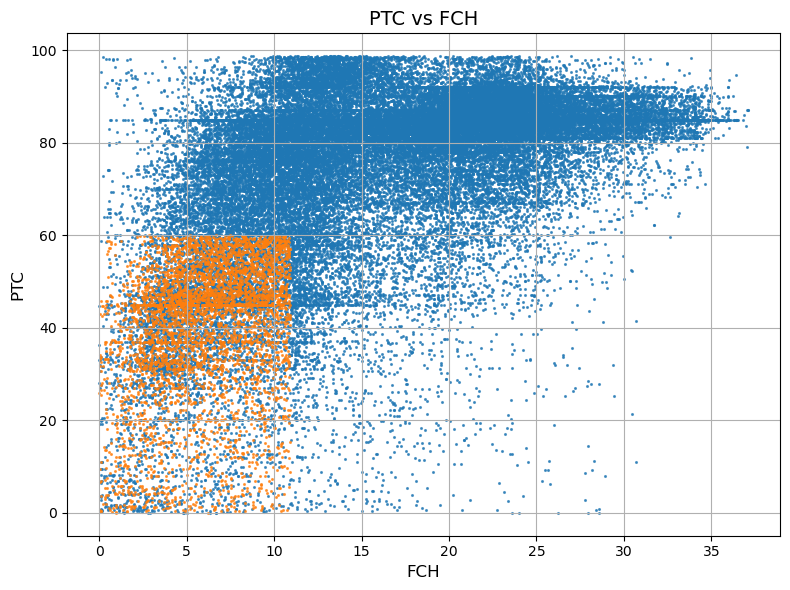

In [11]:
plt.clf()
plt.figure(figsize=(8, 6))
plt.scatter(X[train_mask], Y[train_mask],
            s=1.5, alpha=0.7)
plt.scatter(X[test_mask], Y[test_mask],
            s=1.5, alpha=0.7)
plt.title('PTC vs FCH', fontsize=14)
plt.xlabel('FCH', fontsize=12)
plt.ylabel('PTC', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

## Spatial distribution of the held-out test region

<Figure size 640x480 with 0 Axes>

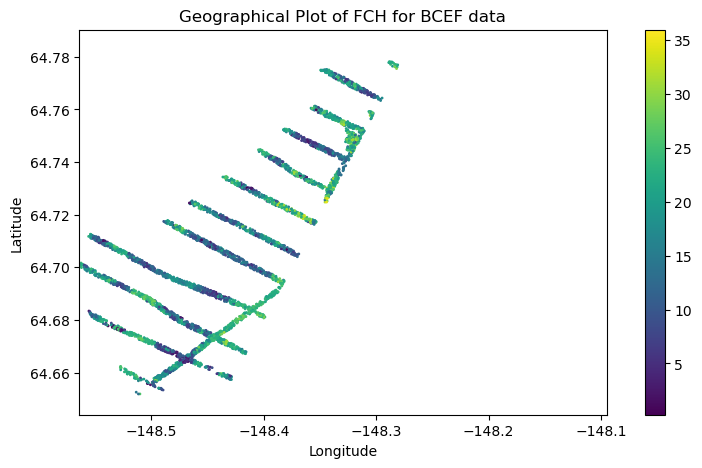

<Figure size 640x480 with 0 Axes>

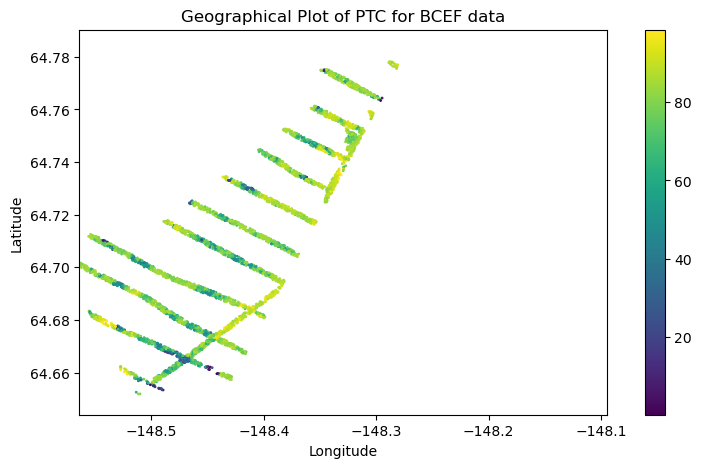

In [12]:
for variable in ['FCH', 'PTC']:
    plt.clf()
    combined_data_test.plot(column=variable, cmap='viridis', legend=True, figsize=(10, 5), markersize=1)
    plt.title('Geographical Plot of ' + variable + ' for BCEF data')
    plt.ylim(combined_data_subsample['latitude'].min(), combined_data_subsample['latitude'].max())
    plt.xlim(combined_data_subsample['longitude'].min(), combined_data_subsample['longitude'].max())
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.show()

## Build graphs for each split

In [13]:
data_train = geospaNN.make_graph(X[train_mask, :], Y[train_mask], coord[train_mask, :], nn)
data_val = geospaNN.make_graph(X[val_mask, :], Y[val_mask], coord[val_mask, :], nn)
data_test = geospaNN.make_graph(X[test_mask, :], Y[test_mask], coord[test_mask, :], nn)

## Model 1: plain neural network + kriging

Train a small MLP (FCH -> 50 -> 20 -> 1) on the mean function, then estimate the
spatial covariance parameters `theta` from the residuals and wrap everything in an
`nngls` object to obtain kriging-corrected predictions. Note this NN ignores spatial
correlation during training; the kriging step is applied afterward.

In [14]:
start_time = time.time()
torch.manual_seed(2024)
mlp_nn = torch.nn.Sequential(
    torch.nn.Linear(p, 50),
    torch.nn.ReLU(),
    torch.nn.Linear(50, 20),
    torch.nn.ReLU(),
    torch.nn.Linear(20, 1),
)
nn_model = geospaNN.nn_train(mlp_nn, lr=0.01, min_delta=0.001)
training_log = nn_model.train(data_train, data_val, data_test)

theta = geospaNN.theta_update(
    mlp_nn(data_train.x).squeeze() - data_train.y,
    data_train.pos, neighbor_size=20
)
model = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_nn,
                       theta=torch.tensor(theta))
estimate_nn = model.estimate(data_test.x)
predict_nn = model.predict(data_train, data_test)

mid_time = time.time()
print(f"NN + kriging done in {mid_time - start_time:.1f}s")

INFO: Early stopping
End at epoch79
---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 56266 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[2.85308272e+02 1.52717341e+02 2.39978206e-02]
NN + kriging done in 31.9s


## Model 2: NNGLS

NNGLS retrains the (copied) MLP using generalized least squares, so the spatial
correlation structure feeds back into the mean-function fit. After training, the
covariance parameters are re-estimated and final predictions are produced.

In [15]:
torch.manual_seed(2024)
mlp_nngls = copy.deepcopy(mlp_nn)
model = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_nngls,
                       theta=torch.tensor(theta, dtype=float))
nngls_model = geospaNN.nngls_train(model, lr=0.1, min_delta=0.001)
training_log = nngls_model.train(
    data_train, data_val, data_test, batch_size=batch_size,
    Update_init=20, Update_step=5, epoch_num=20, vignette=False
)

theta_hat = geospaNN.theta_update(
    mlp_nngls(data_train.x).squeeze() - data_train.y,
    data_train.pos, neighbor_size=20
)
model = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_nngls,
                       theta=torch.tensor(theta_hat))
estimate_nngls = model.estimate(data_test.x)
predict_nngls = model.predict(data_train, data_test)
end_time = time.time()
print(f"NNGLS done in {end_time - mid_time:.1f}s")

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 56266 observations.

Number of covariates 1 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------


  
   
Please check the new documentation with ?BRISC_estimation.
  


Theta estimated as
[5.07137694e+02 5.84751930e+01 1.00000000e-03]
NNGLS done in 3089.6s


## Model 3: linear kriging (BRISC baseline)

`BRISC_estimation` fits a linear spatial model (intercept + FCH) and estimates the
covariance parameters. The fitted linear mean is plugged into the same `nngls`
prediction machinery for an apples-to-apples comparison.

In [16]:
beta, theta_hat_BRISC = geospaNN.BRISC_estimation(
    data_train.y.detach().numpy(),
    torch.concat([torch.ones(data_train.x.shape[0], 1), data_train.x], axis=1).detach().numpy(),
    data_train.pos.detach().numpy()
)

def mlp_BRISC(X):
    return beta[0] + beta[1] * X

model = geospaNN.nngls(p=p, neighbor_size=nn, coord_dimensions=2, mlp=mlp_BRISC,
                       theta=torch.tensor(theta_hat))
estimate_BRISC = model.estimate(data_test.x)
predict_BRISC = model.predict(data_train, data_test)
BRISC_time = time.time()
print("Theta estimated as")
print(theta_hat_BRISC)

---------------------------------------- 
	Ordering Coordinates 
----------------------------------------
	Model description
----------------------------------------
BRISC model fit with 56266 observations.

Number of covariates 2 (including intercept if specified).

Using the exponential spatial correlation model.

Using 15 nearest neighbors.


Source compiled with OpenMP support and model fit using 1 thread(s).
----------------------------------------
	Building neighbor index
----------------------------------------
	Performing optimization
----------------------------------------
	Processing optimizers
----------------------------------------
Theta estimated as
[5.78671748e+02 5.08267898e+01 1.00000000e-03]


## Estimated mean functions

The fitted mean function (PTC as a function of FCH) for each method, overlaid on the
training data. This shows how the NN and NNGLS capture nonlinearity that the linear
baseline cannot.

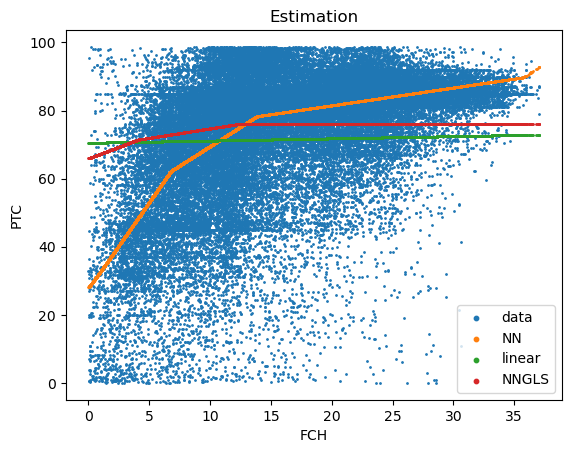

In [17]:
X_plt = data_train.x
Y_plt = data_train.y
plt.clf()
plt.scatter(X_plt.detach().numpy(), Y_plt.detach().numpy(), s=1, label='data')
plt.scatter(X_plt.detach().numpy(), mlp_nn(X_plt).detach().numpy(), s=1, label='NN')
plt.scatter(X_plt.detach().numpy(), mlp_BRISC(X_plt).detach().numpy(), s=1, label='linear')
plt.scatter(X_plt.detach().numpy(), mlp_nngls(X_plt).detach().numpy(), s=1, label='NNGLS')
lgnd = plt.legend(fontsize=10)
plt.xlabel('FCH', fontsize=10)
plt.ylabel('PTC', fontsize=10)
plt.title('Estimation')

for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

## Observed vs predicted on the test region

Predicted PTC against observed PTC for the held-out spatial block. Points on the
diagonal (the `Truth` line) are perfect predictions.

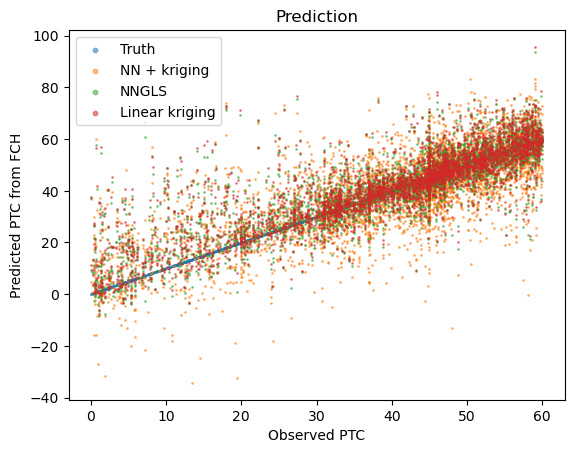

In [18]:
plt.clf()
plt.scatter(data_test.y.detach().numpy(), data_test.y.detach().numpy(), s=1, alpha=0.5, label='Truth')
plt.scatter(data_test.y.detach().numpy(), predict_nn, s=1, alpha=0.5, label='NN + kriging')
plt.scatter(data_test.y.detach().numpy(), predict_nngls, s=1, alpha=0.5, label='NNGLS')
plt.scatter(data_test.y.detach().numpy(), predict_BRISC, s=1, alpha=0.5, label='Linear kriging')
lgnd = plt.legend(fontsize=10)
plt.xlabel('Observed PTC', fontsize=10)
plt.ylabel('Predicted PTC from FCH', fontsize=10)
plt.title('Prediction')

for handle in lgnd.legend_handles:
    handle.set_sizes([10.0])
plt.show()

## Test-set mean squared error

Lower is better. This is the headline comparison between the three methods.

In [19]:
mse_nn = torch.mean((data_test.y - predict_nn) ** 2)
mse_nngls = torch.mean((data_test.y - predict_nngls) ** 2)
mse_brisc = torch.mean((data_test.y - predict_BRISC) ** 2)

print(f"NN + kriging   MSE: {mse_nn:.4f}")
print(f"NNGLS          MSE: {mse_nngls:.4f}")
print(f"Linear kriging MSE: {mse_brisc:.4f}")

NN + kriging   MSE: 124.4704
NNGLS          MSE: 70.1310
Linear kriging MSE: 71.2761
